In [2]:
import torch

In [3]:
print(torch.__version__)

2.15.0+cpu


In [4]:
print(torch.cuda.is_available())

False


In [5]:
x = torch.tensor([1, 2, 3])
x

tensor([1, 2, 3])

In [6]:
y = torch.tensor([[2, 3, 4], [5, 6, 8]])
y

tensor([[2, 3, 4],
        [5, 6, 8]])

In [7]:
x.shape, y.shape

(torch.Size([3]), torch.Size([2, 3]))

In [8]:
x1 = torch.zeros(6)
x1

tensor([0., 0., 0., 0., 0., 0.])

In [9]:
x.dtype

torch.int64

In [10]:
x = torch.tensor([1.0, 2.0, 3.0])
x.dtype

torch.float32

In [11]:
print(y.dtype)

torch.int64


In [12]:
y2 = y.to(torch.float32)
y2

tensor([[2., 3., 4.],
        [5., 6., 8.]])

In [13]:
x2 = torch.ones(2, 3)
x2

tensor([[1., 1., 1.],
        [1., 1., 1.]])

In [14]:
z = torch.randn(5, 6)
z

tensor([[ 1.4337, -1.8792,  1.0215, -0.5280,  0.7344, -2.0406],
        [ 0.4263,  0.2635,  1.3520, -1.1550, -1.2157,  0.3258],
        [-0.2460, -0.4571,  0.9940, -0.6726, -0.7268, -0.5316],
        [ 0.1084, -0.5065, -2.6044,  0.3306,  0.1169, -0.6275],
        [ 0.9255, -0.7207, -0.4993,  0.1110, -0.6286, -1.8687]])

In [15]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cpu')

In [16]:
z = z.to(device)
z.device

device(type='cpu')

In [17]:
A = torch.tensor([[1, 2, 3], [4, 5, 6]]).to(device)
B = torch.tensor([[5, 1, 6], [9, 2, 1]]).to(device)
C = A + B
C

tensor([[ 6,  3,  9],
        [13,  7,  7]])

In [18]:
C = A * B
C

tensor([[ 5,  2, 18],
        [36, 10,  6]])

In [19]:
B = torch.tensor([[5, 1, 6], [9, 2, 1], [3, 4, 7]]).to(device)
C = A @ B
C

tensor([[32, 17, 29],
        [83, 38, 71]])

In [20]:
x = torch.tensor(2.0)
w = torch.tensor(3.0, requires_grad=True)
b = torch.tensor(1.0, requires_grad=True)

y = w * x + b
loss = (y - 10) ** 2
print(y, loss)

tensor(7., grad_fn=<AddBackward0>) tensor(9., grad_fn=<PowBackward0>)


In [21]:
loss.backward()
print(w.grad.item())
print(b.grad.item())

-12.0
-6.0


In [22]:
x = torch.tensor(3.0)
w = torch.tensor(4.0, requires_grad=True)
b = torch.tensor(6.0, requires_grad=True)

y = w * x + b
loss = (y - 10) ** 2
print(y, loss)

tensor(18., grad_fn=<AddBackward0>) tensor(64., grad_fn=<PowBackward0>)


In [23]:
loss.backward()
print(w.grad.item())
print(b.grad.item())

48.0
16.0


In [24]:
y = w * x + b
loss = (y - 10) ** 2

dw, db = torch.autograd.grad(loss, (w, b))
print(dw.item(), db.item())

48.0 16.0


In [25]:
import torch

In [26]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cpu')

In [27]:
X = torch.linspace(-2, 2, 50).unsqueeze(1)
X.shape

torch.Size([50, 1])

In [28]:
noise = 0.6 * torch.randn_like(X)
y = 3 * X + 2 + noise

In [29]:
import matplotlib.pyplot as plt

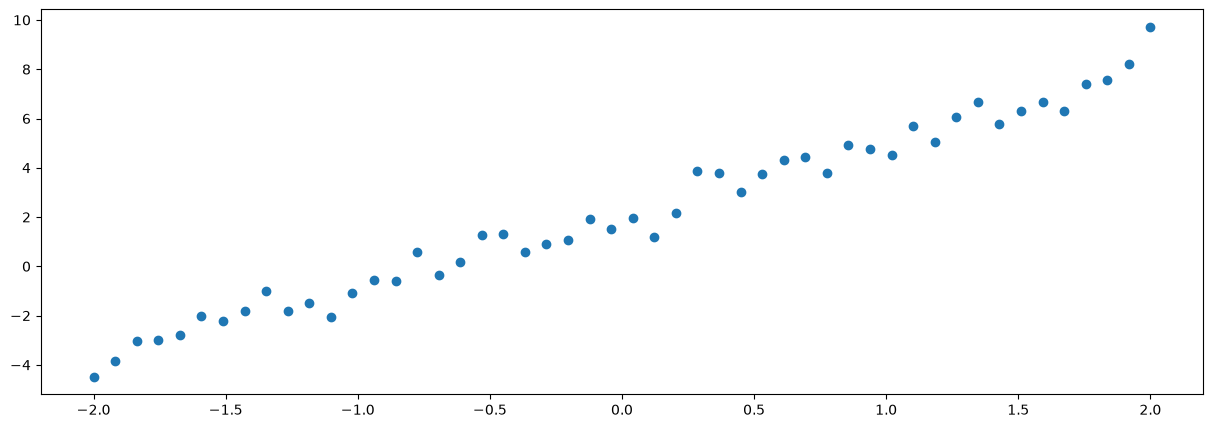

In [30]:
plt.figure(figsize=(15, 5))
plt.scatter(X, y)
plt.show()

In [31]:
import torch.nn as nn

In [32]:
model = nn.Linear(1, 1)

In [33]:
loss_function = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.1)

In [34]:
epochs = 1000
losses = []

model.train()
for epoch in range(epochs):
    y_pred = model(X)
    loss = loss_function(y_pred, y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if epoch % 100 == 0:
        print(f"Epoch : {epoch}/{epochs}, loss = {loss.item():.4f}")

Epoch : 0/1000, loss = 21.1745
Epoch : 100/1000, loss = 0.2891
Epoch : 200/1000, loss = 0.2888
Epoch : 300/1000, loss = 0.2888
Epoch : 400/1000, loss = 0.2888
Epoch : 500/1000, loss = 0.2888
Epoch : 600/1000, loss = 0.2888
Epoch : 700/1000, loss = 0.2888
Epoch : 800/1000, loss = 0.2888
Epoch : 900/1000, loss = 0.2888


In [35]:
model.eval()
with torch.inference_mode():
    pred = model(X)

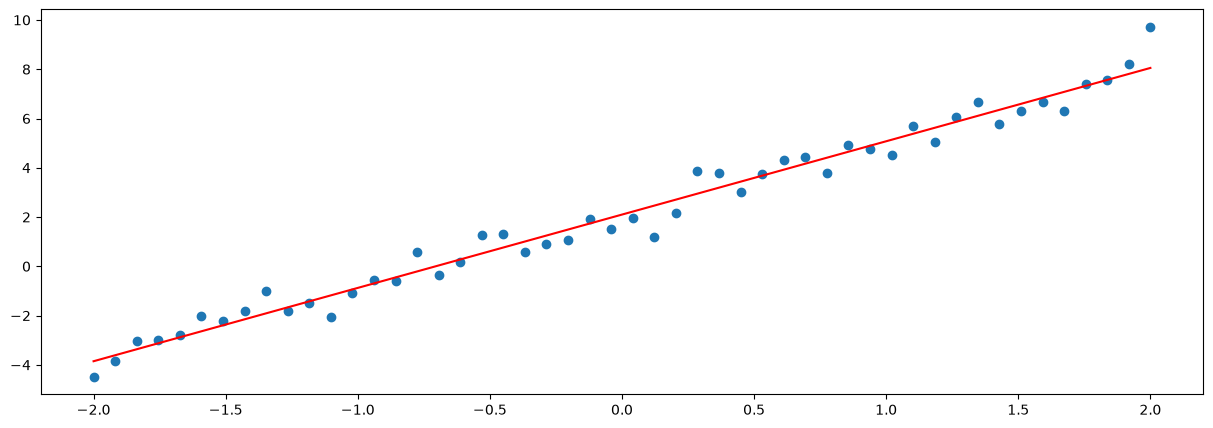

In [36]:
plt.figure(figsize=(15, 5))
plt.scatter(X, y)
plt.plot(X, pred, color="red")
plt.show()

In [37]:
from torcheval.metrics import R2Score

c:\Users\tmt\Desktop\TP_Pytorch\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [38]:
r2_score = R2Score()
r2_score.update(pred, y)
score = r2_score.compute()
score

tensor(0.9770)

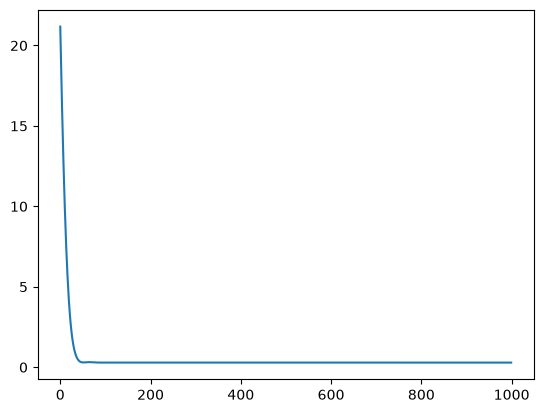

In [39]:
plt.plot(losses)
plt.show()

In [40]:
model = nn.Sequential(
    nn.Linear(4, 16),
    nn.ReLU(),
    nn.Linear(16, 8),
    nn.ReLU(),
    nn.Linear(8, 3)
)
model

Sequential(
  (0): Linear(in_features=4, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=8, bias=True)
  (3): ReLU()
  (4): Linear(in_features=8, out_features=3, bias=True)
)

In [41]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(4, 16),
            nn.ReLU(),
            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Linear(8, 3)
        )

    def forward(self, x):
        return self.net(x)


model = MLP()
model

MLP(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=3, bias=True)
  )
)

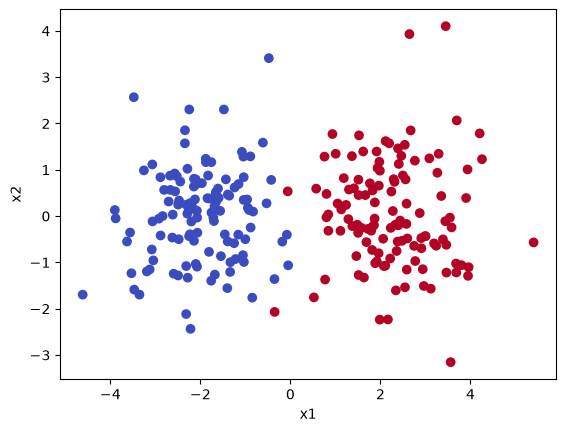

In [42]:
torch.manual_seed(0)

n = 120
class0 = torch.randn(n, 2) + torch.tensor([-2.0, 0.0])
class1 = torch.randn(n, 2) + torch.tensor([2.0, 0.0])

X_cls = torch.cat([class0, class1], dim=0)
y_cls = torch.cat([torch.zeros(n), torch.ones(n)]).long()

plt.scatter(X_cls[:, 0], X_cls[:, 1], c=y_cls, cmap="coolwarm")
plt.xlabel("x1")
plt.ylabel("x2")
plt.show()

In [43]:
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 16),
            nn.ReLU(),
            nn.Linear(16, 16),
            nn.ReLU(),
            nn.Linear(16, 2)
        )

    def forward(self, x):
        return self.net(x)


model_cls = Classifier()
loss_function_cls = nn.CrossEntropyLoss()
optimizer_cls = torch.optim.Adam(model_cls.parameters(), lr=0.01)

In [44]:
epochs = 200
losses_cls = []

model_cls.train()
for epoch in range(epochs):
    logits = model_cls(X_cls)
    loss = loss_function_cls(logits, y_cls)
    optimizer_cls.zero_grad()
    loss.backward()
    optimizer_cls.step()
    losses_cls.append(loss.item())

print("Loss finale :", losses_cls[-1])

Loss finale : 0.0012076839338988066


In [45]:
model_cls.eval()
with torch.inference_mode():
    pred_cls = model_cls(X_cls).argmax(dim=1)

accuracy = (pred_cls == y_cls).float().mean()
print(f"Accuracy = {accuracy.item():.2%}")

Accuracy = 100.00%


In [46]:
from torcheval.metrics import BinaryPrecision, BinaryRecall, BinaryF1Score

for nom, metrique in [("Precision", BinaryPrecision()), ("Recall", BinaryRecall()), ("F1-score", BinaryF1Score())]:
    metrique.update(pred_cls, y_cls)
    print(nom, ":", metrique.compute().item())

Precision : 1.0
Recall : 1.0
F1-score : 1.0


tensor([[120,   0],
        [  0, 120]])


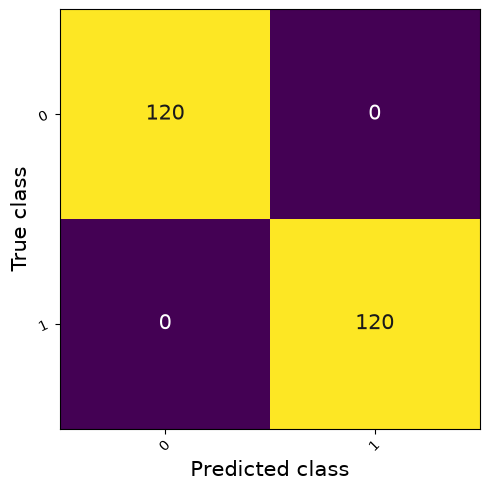

In [47]:
from torchmetrics.classification import BinaryConfusionMatrix

cm = BinaryConfusionMatrix()
matrice = cm(pred_cls, y_cls)
print(matrice)
cm.plot()
plt.show()

# Partie 2 — Exercices

### Exercice 1 : Régression

Prédire le salaire selon l’ancienneté et le niveau d’expertise

Objectif:

Construire un modèle de régression linéaire multiple pour prédire le salaire mensuel à partir de deux variables :
- Ancienneté : nombre d’années d’expérience.
- Niveau d’expertise : note de 1 à 5.
Le modèle doit apprendre la relation :

Salaire = w_1 * Ancienneté + w_2 * Expertise + b 

Les salaires sont exprimés en dirhams (DH). Les données sont fictives et servent uniquement à l’apprentissage.

1. *Générer les données*

Pour cet exercice, on suppose que les salaires suivent approximativement la règle : Salaire = 4000 + 600 * Ancienneté + 1500 * Expertise} + Bruit
Le bruit représente les variations individuelles non expliquées par les deux variables.

In [48]:
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

# Nombre de salariés
n = 300

# Ancienneté : de 0 à 20 ans
anciennete = torch.randint(0, 21, (n, 1)).float()

# Expertise : de 1 à 5
expertise = torch.randint(1, 6, (n, 1)).float()

# Variations aléatoires des salaires
bruit = torch.randn(n, 1) * 500

# Salaire mensuel en DH
salaires = (
    4000
    + 600 * anciennete
    + 1500 * expertise
    + bruit
)

# Matrice des entrées : dimensions (300, 2)
X = torch.cat([anciennete, expertise], dim=1)

# Sortie : dimensions (300, 1)
y = salaires

for i in range(5):
    print(
        f"Ancienneté : {X[i, 0].item():.0f} ans | "
        f"Expertise : {X[i, 1].item():.0f}/5 | "
        f"Salaire : {y[i, 0].item():.2f} DH"
    )

Ancienneté : 15 ans | Expertise : 2/5 | Salaire : 16262.90 DH
Ancienneté : 2 ans | Expertise : 3/5 | Salaire : 10541.39 DH
Ancienneté : 4 ans | Expertise : 3/5 | Salaire : 10948.37 DH
Ancienneté : 19 ans | Expertise : 3/5 | Salaire : 20028.54 DH
Ancienneté : 18 ans | Expertise : 2/5 | Salaire : 18036.38 DH


**Travail demandé**

- Affichez les dimensions de X et de y.
- Calculez le salaire moyen.
- Tracez un nuage de points représentant le salaire selon l’ancienneté, avec une couleur différente selon l’expertise.


Dimensions de X : torch.Size([300, 2])
Dimensions de y : torch.Size([300, 1])
Salaire moyen : 15010.55 DH


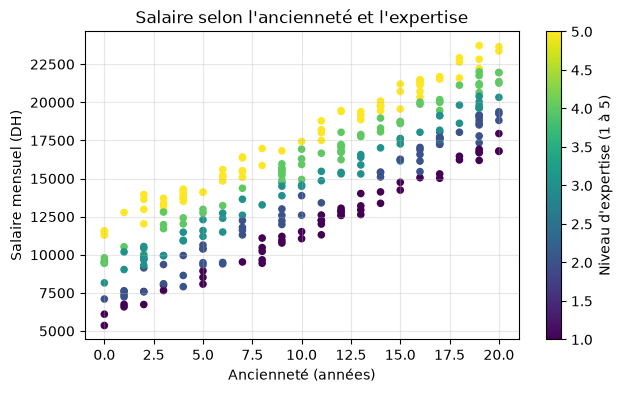

In [49]:
# Dimensions des données
print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

# Salaire moyen
print(f"Salaire moyen : {y.mean().item():.2f} DH")

# Nuage de points : salaire selon l'ancienneté, couleur selon l'expertise
plt.figure(figsize=(7, 4))
nuage = plt.scatter(
    X[:, 0].numpy(), y[:, 0].numpy(),
    c=X[:, 1].numpy(), cmap="viridis", s=20
)
plt.colorbar(nuage, label="Niveau d'expertise (1 à 5)")
plt.xlabel("Ancienneté (années)")
plt.ylabel("Salaire mensuel (DH)")
plt.title("Salaire selon l'ancienneté et l'expertise")
plt.grid(alpha=0.3)
plt.show()

2. *Séparer et préparer les données*
Utilisez 80 % des données pour l’entraînement et 20 % pour le test.

Pour faciliter l’apprentissage :

standardisez les entrées à partir des statistiques du jeu d’entraînement ;
exprimez les salaires en milliers de DH.

In [50]:
indices = torch.randperm(n)
limite = int(0.8 * n)

train_indices = indices[:limite]
test_indices = indices[limite:]

X_train = X[train_indices]
X_test = X[test_indices]

y_train = y[train_indices] / 1000
y_test = y[test_indices] / 1000

# Statistiques calculées uniquement sur le jeu d'entraînement
moyenne = X_train.mean(dim=0, keepdim=True)
ecart_type = X_train.std(dim=0, keepdim=True)

X_train_norm = (X_train - moyenne) / ecart_type
X_test_norm = (X_test - moyenne) / ecart_type

3. *Construire et entraîner le modèle*

In [51]:
# Deux variables d'entrée et une sortie
model = nn.Linear(2, 1)

# Erreur quadratique moyenne
criterion = nn.MSELoss()

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.05
)

historique = []

model.train()

for epoch in range(500):
    # 1. Réinitialiser les gradients
    optimizer.zero_grad()

    # 2. Prédire les salaires
    predictions = model(X_train_norm)

    # 3. Calculer la perte
    loss = criterion(predictions, y_train)

    # 4. Calculer les gradients
    loss.backward()

    # 5. Mettre à jour les paramètres
    optimizer.step()

    historique.append(loss.item())

    if (epoch + 1) % 100 == 0:
        print(
            f"Époque {epoch + 1} | "
            f"Perte : {loss.item():.4f}"
        )

Époque 100 | Perte : 0.2391
Époque 200 | Perte : 0.2391
Époque 300 | Perte : 0.2391
Époque 400 | Perte : 0.2391
Époque 500 | Perte : 0.2391


Travail demandé :

- Complétez le modèle et la boucle d’entraînement.
- Tracez l’évolution de la perte :


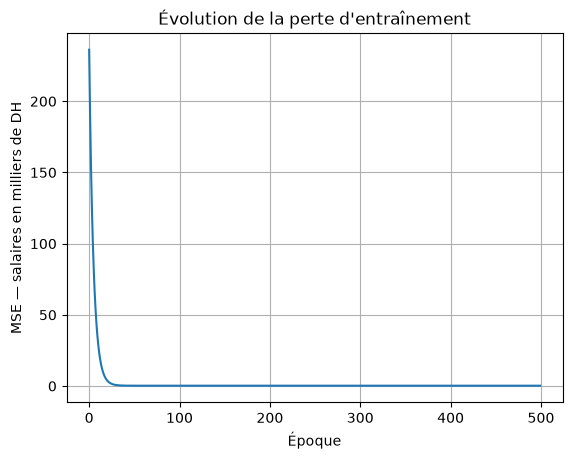

In [52]:
plt.plot(historique)
plt.xlabel("Époque")
plt.ylabel("MSE — salaires en milliers de DH")
plt.title("Évolution de la perte d'entraînement")
plt.grid()
plt.show()

4. Évaluer les prédictions

In [53]:
model.eval()

with torch.no_grad():
    predictions_test = model(X_test_norm)

    # Conversion en DH
    predictions_dh = predictions_test * 1000
    salaires_reels_dh = y_test * 1000

    # Erreur absolue moyenne
    mae = (predictions_dh - salaires_reels_dh).abs().mean()

print(f"Erreur absolue moyenne : {mae.item():.2f} DH")

Erreur absolue moyenne : 381.64 DH


Interprétation : une MAE de 400 DH signifie que les prédictions s’écartent, en moyenne, de 400 DH des salaires réels.

5. Prédire le salaire d’un nouveau salarié

Prédisez le salaire d’une personne ayant :

- 7 ans d’ancienneté ;
- un niveau d’expertise de 4/5.

In [54]:
nouveau_salarie = torch.tensor([[7.0, 4.0]])

# Appliquer la même normalisation qu'à l'entraînement
nouveau_salarie_norm = (nouveau_salarie - moyenne) / ecart_type

with torch.no_grad():
    # Le modèle prédit en milliers de DH : on remultiplie par 1000
    salaire_predit = model(nouveau_salarie_norm) * 1000

print(f"Salaire estimé : {salaire_predit.item():.2f} DH")

Salaire estimé : 14201.94 DH


Vérification : d’après la règle de génération, le salaire sans bruit est :

4000 + 600 * 7 + 1500 * 4 = 14200 DH

Votre prédiction devrait être proche de cette valeur.

Questions complémentaires :

- À expertise constante, quel est l’effet d’une année d’ancienneté supplémentaire ?
- Pourquoi la perte ne devient-elle pas exactement nulle ?
- Le modèle est-il fiable pour une ancienneté de 40 ans, absente des données d’entraînement ?
- Quel effet aurait une augmentation du bruit sur la précision ?
- Retrouvez les coefficients en unités d’origine à partir des paramètres du modèle entraîné. Ils devraient être proches de 600, 1500 et 4000.

Remarque : traiter l’expertise comme une note numérique suppose que chaque passage d’un niveau au suivant a le même effet sur le salaire. Cette hypothèse simplifie l’exercice, mais doit être vérifiée avec des données réelles.

In [55]:
# Retrouver les coefficients en unités d'origine
# Le modèle a appris : y_milliers = w · (x - moyenne) / ecart_type + b
w = model.weight.data[0]
b = model.bias.data[0]

w_origine = w / ecart_type[0] * 1000
b_origine = (b - (w * moyenne[0] / ecart_type[0]).sum()) * 1000

print(f"Effet d'une année d'ancienneté : {w_origine[0].item():.0f} DH (attendu : 600)")
print(f"Effet d'un niveau d'expertise   : {w_origine[1].item():.0f} DH (attendu : 1500)")
print(f"Salaire de base (b)             : {b_origine.item():.0f} DH (attendu : 4000)")

Effet d'une année d'ancienneté : 593 DH (attendu : 600)
Effet d'un niveau d'expertise   : 1491 DH (attendu : 1500)
Salaire de base (b)             : 4090 DH (attendu : 4000)


**Réponses aux questions complémentaires**

- **Effet d'une année d'ancienneté :** à expertise constante, une année supplémentaire augmente le salaire d'environ **600 DH** (coefficient $w_1$ retrouvé ci-dessus).
- **Pourquoi la perte n'est pas nulle :** les salaires contiennent un bruit aléatoire (écart-type de 500 DH) qui ne dépend ni de l'ancienneté ni de l'expertise. Aucun modèle ne peut prédire ce bruit, donc l'erreur ne peut pas descendre à zéro. La MSE minimale est d'environ $0{,}5^2 = 0{,}25$ (en milliers de DH au carré).
- **Ancienneté de 40 ans :** le modèle n'est pas fiable, car les données d'entraînement vont seulement de 0 à 20 ans. Prédire en dehors de cet intervalle est une **extrapolation** : rien ne garantit que la relation reste linéaire au-delà.
- **Augmentation du bruit :** plus le bruit est grand, plus la perte et la MAE augmentent, et plus les coefficients estimés s'éloignent des vraies valeurs (surtout avec seulement 240 exemples d'entraînement).
- **Coefficients en unités d'origine :** on obtient des valeurs proches de **600**, **1500** et **4000**, ce qui montre que le modèle a bien retrouvé la règle de génération des données.

### Exercice 2 — Classification des fleurs Iris 🌸

Objectif : entraîner un réseau de neurones pour prédire l'espèce d'une fleur à partir de quatre mesures :

- longueur et largeur des sépales ;
- longueur et largeur des pétales.

Le jeu de données Iris contient 150 fleurs réparties en trois classes : setosa, versicolor et virginica.

Bibliothèques : torch, scikit-learn.

**1. Préparation des données**

In [56]:
import torch
from torch import nn
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

torch.manual_seed(42)

# Charger les données
iris = load_iris()
X, y = iris.data, iris.target

# Séparer les données : 80 % entraînement, 20 % test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Ajuster la normalisation uniquement sur l'entraînement
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Convertir en tenseurs
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

print("Dimensions :", X_train.shape, y_train.shape)

Dimensions : torch.Size([120, 4]) torch.Size([120])


**Questions :**

- Que représentent les quatre colonnes de X_train ?
- Pourquoi utilise-t-on torch.long pour les étiquettes ?
- Pourquoi ne faut-il pas ajuster le StandardScaler sur les données de test ?

**Réponses :**

- Les quatre colonnes de `X_train` sont : la **longueur du sépale**, la **largeur du sépale**, la **longueur du pétale** et la **largeur du pétale** (en cm, ici standardisées).
- On utilise `torch.long` car `CrossEntropyLoss` attend des **indices de classe entiers** (0, 1 ou 2), pas des nombres réels.
- On n'ajuste pas le `StandardScaler` sur le test pour éviter une **fuite de données** : la moyenne et l'écart-type doivent venir uniquement de l'entraînement, sinon le modèle profiterait d'informations sur le test et l'évaluation serait trop optimiste.

**2. Construire le réseau**

In [57]:
model = nn.Sequential(
    nn.Linear(4, 16),   # 4 mesures en entrée, 16 neurones cachés
    nn.ReLU(),
    nn.Linear(16, 3)    # 3 scores en sortie (une par espèce)
)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

Attention : n’ajoutez pas de Softmax à la sortie. CrossEntropyLoss attend directement les scores bruts, appelés logits.

**3. Entraîner le modèle**

Complétez la boucle d’entraînement. Pour cet exercice, chaque itération utilise toutes les données d’entraînement.

In [58]:
epochs = 200
losses = []

model.train()

for epoch in range(epochs):
    # Remettre les gradients à zéro
    optimizer.zero_grad()

    # Calculer les scores prédits
    logits = model(X_train)

    # Calculer la perte
    loss = criterion(logits, y_train)

    # Calculer les gradients
    loss.backward()

    # Mettre à jour les paramètres
    optimizer.step()

    losses.append(loss.item())

    if (epoch + 1) % 20 == 0:
        print(f"Époque {epoch + 1:3d} | Perte : {loss.item():.4f}")

Époque  20 | Perte : 0.3695
Époque  40 | Perte : 0.1923
Époque  60 | Perte : 0.1063
Époque  80 | Perte : 0.0724
Époque 100 | Perte : 0.0590
Époque 120 | Perte : 0.0525
Époque 140 | Perte : 0.0488
Époque 160 | Perte : 0.0463
Époque 180 | Perte : 0.0445
Époque 200 | Perte : 0.0432


**4. Évaluer le classifieur**

Complétez le calcul des prédictions et de l’accuracy, c’est-à-dire la proportion de fleurs correctement classées.

In [59]:
model.eval()

with torch.no_grad():
    logits = model(X_test)

    # Classe au score maximal pour chaque fleur
    predictions = logits.argmax(dim=1)

    # Proportion de prédictions correctes
    accuracy = (predictions == y_test).float().mean()

print(f"Accuracy sur le test : {accuracy.item():.1%}")

Accuracy sur le test : 100.0%


**5- Autres question :**

- Tracez la courbe de perte.
- Affichez une matrice de confusion.
- Comparez ce réseau à un modèle sans couche cachée : nn.Linear(4, 3).
- Prédisez l’espèce d’une nouvelle fleur de mesures [5.1, 3.5, 1.4, 0.2], après l’avoir normalisée avec le même scaler.

**Courbe de perte**

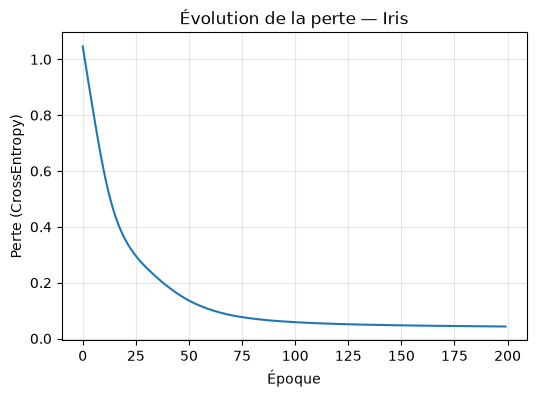

In [60]:
plt.figure(figsize=(6, 4))
plt.plot(losses)
plt.xlabel("Époque")
plt.ylabel("Perte (CrossEntropy)")
plt.title("Évolution de la perte — Iris")
plt.grid(alpha=0.3)
plt.show()

**Matrice de confusion**

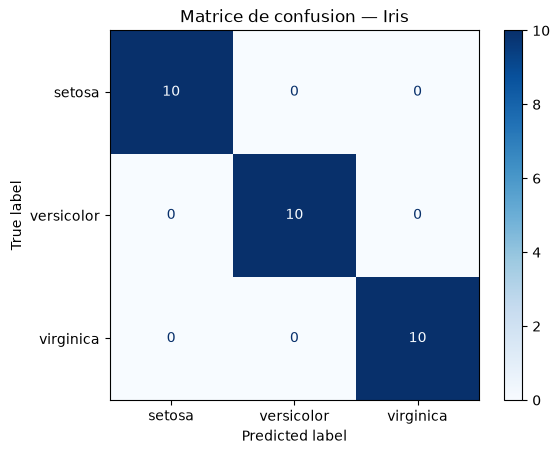

In [61]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test.numpy(),
    predictions.numpy(),
    display_labels=iris.target_names,
    cmap="Blues"
)
plt.title("Matrice de confusion — Iris")
plt.show()

**Comparaison avec un modèle sans couche cachée : `nn.Linear(4, 3)`**

Réseau avec couche cachée : accuracy = 100.0% | perte finale = 0.0432
Modèle linéaire (4 → 3)   : accuracy = 90.0% | perte finale = 0.2416


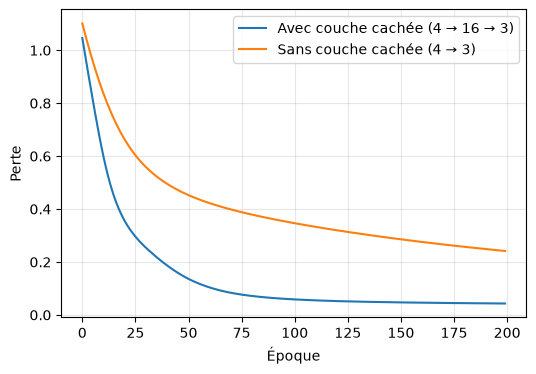

In [62]:
torch.manual_seed(42)

model_lineaire = nn.Linear(4, 3)
optimizer_lin = torch.optim.Adam(model_lineaire.parameters(), lr=0.01)
losses_lin = []

model_lineaire.train()
for epoch in range(epochs):
    optimizer_lin.zero_grad()
    loss_lin = criterion(model_lineaire(X_train), y_train)
    loss_lin.backward()
    optimizer_lin.step()
    losses_lin.append(loss_lin.item())

model_lineaire.eval()
with torch.no_grad():
    pred_lin = model_lineaire(X_test).argmax(dim=1)
    accuracy_lin = (pred_lin == y_test).float().mean()

print(f"Réseau avec couche cachée : accuracy = {accuracy.item():.1%} | perte finale = {losses[-1]:.4f}")
print(f"Modèle linéaire (4 → 3)   : accuracy = {accuracy_lin.item():.1%} | perte finale = {losses_lin[-1]:.4f}")

plt.figure(figsize=(6, 4))
plt.plot(losses, label="Avec couche cachée (4 → 16 → 3)")
plt.plot(losses_lin, label="Sans couche cachée (4 → 3)")
plt.xlabel("Époque")
plt.ylabel("Perte")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Interprétation :** les deux modèles obtiennent une bonne accuracy, car les classes d'Iris sont presque séparables linéairement. Le réseau avec couche cachée descend plus vite et plus bas en perte, car la ReLU lui permet de tracer des frontières non linéaires. Sur un jeu aussi simple, le gain en accuracy reste faible.

**Prédiction pour une nouvelle fleur `[5.1, 3.5, 1.4, 0.2]`**

In [63]:
nouvelle_fleur = [[5.1, 3.5, 1.4, 0.2]]

# Normaliser avec le même scaler que l'entraînement
nouvelle_fleur = scaler.transform(nouvelle_fleur)
nouvelle_fleur = torch.tensor(nouvelle_fleur, dtype=torch.float32)

model.eval()
with torch.no_grad():
    logits_fleur = model(nouvelle_fleur)
    probabilites = torch.softmax(logits_fleur, dim=1)
    classe = logits_fleur.argmax(dim=1).item()

print("Espèce prédite :", iris.target_names[classe])
for nom, p in zip(iris.target_names, probabilites[0]):
    print(f"  {nom:<10} : {p.item():.1%}")

Espèce prédite : setosa
  setosa     : 100.0%
  versicolor : 0.0%
  virginica  : 0.0%


### Exercice 3 : Classifier les chiffres MNIST avec un MLP
Objectif : utiliser des mini-lots et évaluer un modèle sur des données de test.

Chargement des données

In [64]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset, batch_size=64, shuffle=True
)

test_loader = DataLoader(
    test_dataset, batch_size=256, shuffle=False
)

model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

100.0%
100.0%
100.0%
100.0%


#### Travail demandé : 
- Entraînez le modèle pendant 5 époques.
- Utilisez model.train() pendant l’entraînement.
- Évaluez-le avec model.eval() et torch.no_grad().
- Obtenez les classes prédites avec :
   - predicted_classes = outputs.argmax(dim=1)
   - Calculez mes métriques Accuracy, Recall, Precision et f1-Score sur le jeu de test.
   - Afficher la matrice de confusion
   - Affichez quelques images mal classées.
- Sauvegarder et recharger un modèle : réutiliser un réseau entraîné sans recommencer l’apprentissage.

Attention : CrossEntropyLoss attend les sorties brutes du réseau, sans Softmax, et des étiquettes entières.

**Entraînement pendant 5 époques**

In [65]:
epochs = 5
historique_mlp = []

for epoch in range(epochs):
    model.train()
    total_loss = 0.0

    for images, labels in train_loader:
        optimizer.zero_grad()
        outputs = model(images)            # scores bruts (logits)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)

    perte_moyenne = total_loss / len(train_dataset)
    historique_mlp.append(perte_moyenne)
    print(f"Époque {epoch + 1}/{epochs} | Perte : {perte_moyenne:.4f}")

Époque 1/5 | Perte : 0.3430
Époque 2/5 | Perte : 0.1534
Époque 3/5 | Perte : 0.1055
Époque 4/5 | Perte : 0.0798
Époque 5/5 | Perte : 0.0628


**Évaluation sur le jeu de test**

In [66]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    ConfusionMatrixDisplay
)

model.eval()
toutes_predictions = []
toutes_etiquettes = []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)
        predicted_classes = outputs.argmax(dim=1)

        toutes_predictions.append(predicted_classes)
        toutes_etiquettes.append(labels)

y_pred = torch.cat(toutes_predictions).numpy()
y_true = torch.cat(toutes_etiquettes).numpy()

print(f"Accuracy  : {accuracy_score(y_true, y_pred):.4f}")
print(f"Precision : {precision_score(y_true, y_pred, average='macro'):.4f}")
print(f"Recall    : {recall_score(y_true, y_pred, average='macro'):.4f}")
print(f"F1-score  : {f1_score(y_true, y_pred, average='macro'):.4f}")

Accuracy  : 0.9740
Precision : 0.9743
Recall    : 0.9736
F1-score  : 0.9738


**Matrice de confusion**

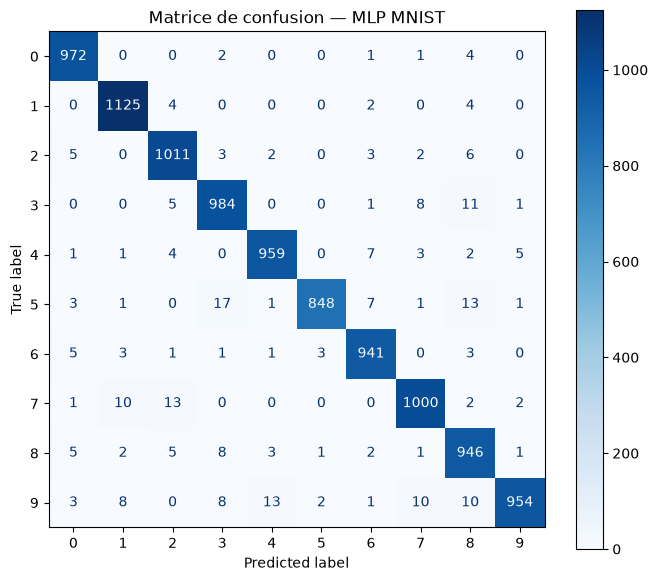

In [67]:
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, cmap="Blues", ax=ax)
ax.set_title("Matrice de confusion — MLP MNIST")
plt.show()

**Quelques images mal classées**

Nombre d'images mal classées : 260 sur 10000


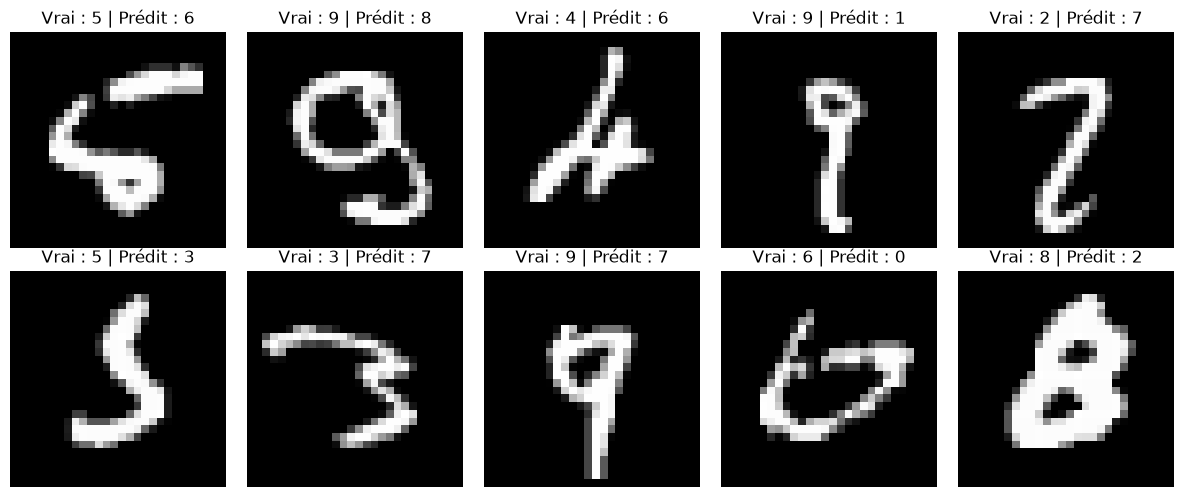

In [68]:
indices_erreurs = (y_pred != y_true).nonzero()[0]
print("Nombre d'images mal classées :", len(indices_erreurs), "sur", len(y_true))

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for ax, i in zip(axes.flat, indices_erreurs[:10]):
    image, vraie_classe = test_dataset[i]
    ax.imshow(image[0], cmap="gray")
    ax.set_title(f"Vrai : {vraie_classe} | Prédit : {y_pred[i]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

**Sauvegarder et recharger le modèle**

In [69]:
# Sauvegarde des paramètres appris
torch.save(model.state_dict(), "mnist_mlp.pth")
print("Modèle sauvegardé dans mnist_mlp.pth")

# Recréer la même architecture puis charger les poids
model_recharge = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
)
model_recharge.load_state_dict(torch.load("mnist_mlp.pth", weights_only=True))
model_recharge.eval()

# Vérification : même accuracy sans réentraîner
correct = 0
with torch.no_grad():
    for images, labels in test_loader:
        correct += (model_recharge(images).argmax(dim=1) == labels).sum().item()

print(f"Accuracy du modèle rechargé : {correct / len(test_dataset):.4f}")

Modèle sauvegardé dans mnist_mlp.pth
Accuracy du modèle rechargé : 0.9740


### Exercice 4 — Classification MNIST avec un CNN

Objectif : construire un réseau de neurones convolutif (CNN) pour reconnaître les chiffres manuscrits de 0 à 9.

MNIST contient 60 000 images d’entraînement et 10 000 images de test, en niveaux de gris, de taille 28 × 28 pixels.

**1. Chargement des données**

In [70]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Appareil :", device)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_dataset = datasets.MNIST(
    root="./data", train=True, download=True, transform=transform
)

test_dataset = datasets.MNIST(
    root="./data", train=False, download=True, transform=transform
)

train_loader = DataLoader(
    train_dataset, batch_size=64, shuffle=True
)

test_loader = DataLoader(
    test_dataset, batch_size=256, shuffle=False
)

images, labels = next(iter(train_loader))

print("Images :", images.shape)  # [64, 1, 28, 28]
print("Labels :", labels.shape)  # [64]

Appareil : cpu
Images : torch.Size([64, 1, 28, 28])
Labels : torch.Size([64])


**Questions :**

- Que représentent les quatre dimensions du tenseur images ?
- Pourquoi mélanger les données d’entraînement avec shuffle=True ?

**Réponses :**

- Le tenseur `images` a la forme `[64, 1, 28, 28]` : **64** images dans le mini-lot (batch), **1** canal (niveaux de gris), **28** pixels de hauteur et **28** pixels de largeur.
- `shuffle=True` mélange les données à chaque époque. Le modèle ne voit pas les exemples toujours dans le même ordre, ce qui évite qu'il apprenne un ordre artificiel et rend la descente de gradient plus stable et plus efficace.

**2. Visualiser quelques images**

Complétez l’affichage des étiquettes :

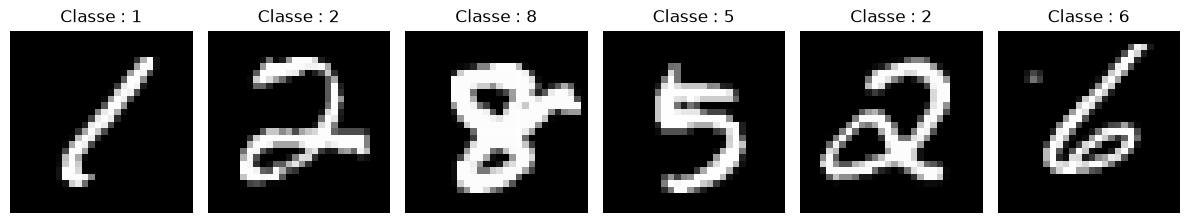

In [71]:
fig, axes = plt.subplots(1, 6, figsize=(12, 3))

for i, ax in enumerate(axes):
    # Annuler la normalisation pour l'affichage
    image = images[i, 0] * 0.3081 + 0.1307

    ax.imshow(image.numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Classe : {labels[i].item()}")
    ax.axis("off")

plt.tight_layout()
plt.show()

**3. Construire le CNN**

Implémentez cette architecture :

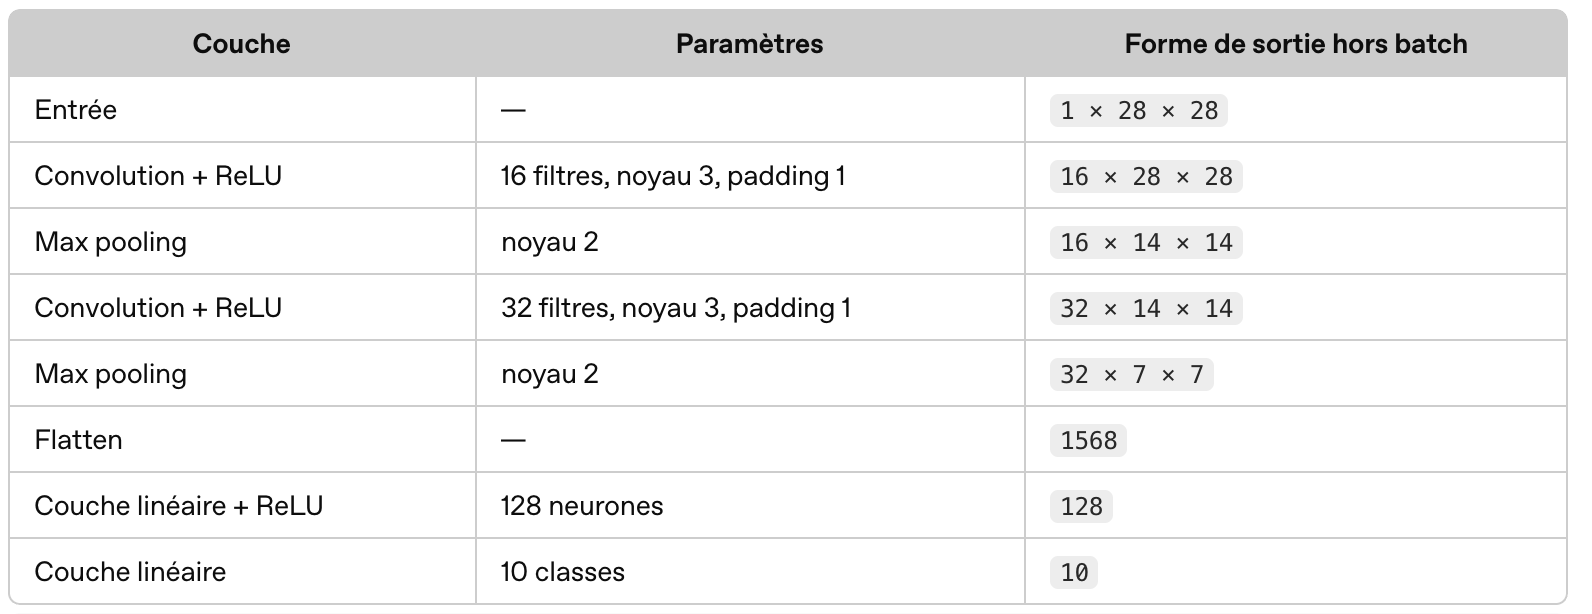

In [72]:
class MNISTClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(
                in_channels=1,
                out_channels=16,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(
                in_channels=16,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


model = MNISTClassifier().to(device)

# Vérifier la forme de sortie
with torch.no_grad():
    output = model(images.to(device))

assert output.shape == (images.size(0), 10)
print("Sortie :", output.shape)

Sortie : torch.Size([64, 10])


**Question :** pourquoi la première couche linéaire reçoit-elle 32 × 7 × 7 valeurs ?

Attention : n’ajoutez pas de Softmax au modèle. CrossEntropyLoss attend les scores bruts, appelés logits.

**Réponse :** avec `padding=1` et un noyau 3 × 3, chaque convolution conserve la taille de l'image. Seuls les max pooling la réduisent, en la divisant par 2 : 28 × 28 → 14 × 14 après le premier, puis 14 × 14 → 7 × 7 après le second. La deuxième convolution produit **32** cartes de caractéristiques, donc après `Flatten` on obtient $32 \times 7 \times 7 = 1568$ valeurs.

**4. Entraîner le réseau**

In [73]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

epochs = 3
loss_history = []

for epoch in range(epochs):
    model.train()
    total_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        # 1. Réinitialiser les gradients
        optimizer.zero_grad()

        # 2. Calculer les scores
        logits = model(images)

        # 3. Calculer la perte
        loss = criterion(logits, labels)

        # 4. Calculer les gradients
        loss.backward()

        # 5. Mettre à jour les paramètres
        optimizer.step()

        total_loss += loss.item() * images.size(0)

    average_loss = total_loss / len(train_dataset)
    loss_history.append(average_loss)

    print(
        f"Époque {epoch + 1}/{epochs} "
        f"| Perte : {average_loss:.4f}"
    )

Époque 1/3 | Perte : 0.1680
Époque 2/3 | Perte : 0.0482
Époque 3/3 | Perte : 0.0351


**5. Évaluer sur le jeu de test**

In [74]:
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        logits = model(images)

        # Classe ayant le score le plus élevé
        predictions = logits.argmax(dim=1)

        # Compter les bonnes prédictions
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

accuracy = correct / total
print(f"Accuracy sur le test : {accuracy:.2%}")

Accuracy sur le test : 98.88%


**Indices :**

- argmax(dim=1) sélectionne une classe pour chaque image ;
(predictions == labels).sum().item() compte les prédictions correctes.

- Résultat attendu : une accuracy généralement supérieure à 97 % après quelques époques, sans garantie exacte.

**Autres questions :**

- Affichez 10 images mal classées, avec leur vraie classe et la prédiction.
- Ajoutez une couche Dropout avant la dernière couche linéaire.
- Sauvegardez les paramètres avec torch.save(model.state_dict(), "mnist_cnn.pth").

**10 images mal classées**

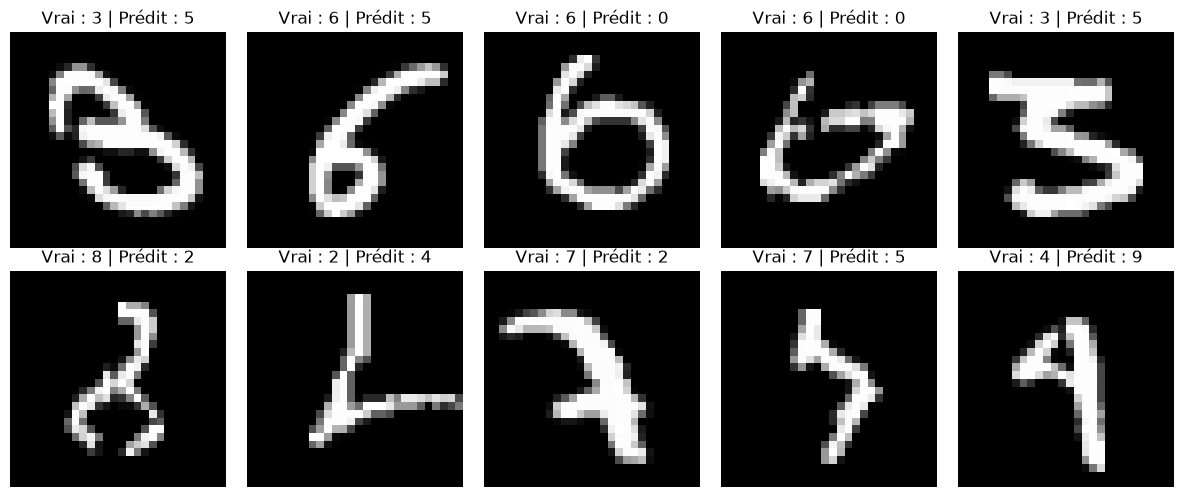

In [75]:
model.eval()
erreurs = []

with torch.no_grad():
    for images, labels in test_loader:
        predictions = model(images.to(device)).argmax(dim=1).cpu()
        masque = predictions != labels

        for image, vraie, predite in zip(images[masque], labels[masque], predictions[masque]):
            erreurs.append((image, vraie.item(), predite.item()))

        if len(erreurs) >= 10:
            break

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for ax, (image, vraie, predite) in zip(axes.flat, erreurs[:10]):
    ax.imshow(image[0] * 0.3081 + 0.1307, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Vrai : {vraie} | Prédit : {predite}")
    ax.axis("off")
plt.tight_layout()
plt.show()

**CNN avec une couche Dropout avant la dernière couche linéaire**

In [76]:
class MNISTClassifierDropout(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(p=0.5),      # désactive 50 % des neurones pendant l'entraînement
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


torch.manual_seed(42)
model_dropout = MNISTClassifierDropout().to(device)
optimizer_dropout = torch.optim.Adam(model_dropout.parameters(), lr=0.001)

for epoch in range(epochs):
    model_dropout.train()           # Dropout actif
    total_loss = 0.0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer_dropout.zero_grad()
        loss = criterion(model_dropout(images), labels)
        loss.backward()
        optimizer_dropout.step()

        total_loss += loss.item() * images.size(0)

    print(f"Époque {epoch + 1}/{epochs} | Perte : {total_loss / len(train_dataset):.4f}")

model_dropout.eval()                # Dropout désactivé pour l'évaluation
correct = 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        correct += (model_dropout(images).argmax(dim=1) == labels).sum().item()

print(f"Accuracy CNN sans Dropout : {accuracy:.2%}")
print(f"Accuracy CNN avec Dropout : {correct / len(test_dataset):.2%}")

Époque 1/3 | Perte : 0.2485
Époque 2/3 | Perte : 0.0869
Époque 3/3 | Perte : 0.0682
Accuracy CNN sans Dropout : 98.88%
Accuracy CNN avec Dropout : 98.82%


**Remarque :** le Dropout éteint aléatoirement une partie des neurones pendant l'entraînement, ce qui réduit le surapprentissage. La perte d'entraînement est un peu plus élevée, mais l'accuracy sur le test reste du même ordre (environ 98–99 %). Il n'est actif qu'en mode `model.train()` et il est automatiquement désactivé par `model.eval()`.

**Sauvegarder et recharger le CNN**

In [77]:
torch.save(model.state_dict(), "mnist_cnn.pth")
print("Modèle sauvegardé dans mnist_cnn.pth")

model_recharge = MNISTClassifier().to(device)
model_recharge.load_state_dict(torch.load("mnist_cnn.pth", map_location=device, weights_only=True))
model_recharge.eval()

correct = 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        correct += (model_recharge(images).argmax(dim=1) == labels).sum().item()

print(f"Accuracy du CNN rechargé : {correct / len(test_dataset):.2%}")

Modèle sauvegardé dans mnist_cnn.pth
Accuracy du CNN rechargé : 98.88%
